# Proyecto Final Integrador: segmentación de clientes con RFM y clustering

**Grupo 5:**
Avaro Lucena
Figueroa Tamara
Méndez Julieta
Milicich Marcos
Robledo Maximiliano.

**Dataset:** Online Retail II (UCI). Transacciones de un comercio mayorista-minorista británico, entre diciembre de 2009 y diciembre de 2011. EXCEL con dos hojas correspondientes a los periodos 2009-2010 y 2010-2011.

**Metodología:** CRISP-DM. Cada sección de este notebook corresponde a una fase.
**Algoritmos evaluados:** K-Means, clustering jerárquico (Ward) y DBSCAN.
**Benchmark de negocio:** segmentación por quintiles RFM
Cada cliente se resume con tres números:

- **R = Recencia:** días desde su última compra. Menos días = cliente más activo.
- **F = Frecuencia:** cantidad de facturas distintas. Más = cliente más fiel.
- **M = Monetario:** total gastado. Más = cliente más valioso.

En vez de mirar cada transacción, miramos un "perfil" por cliente con estos tres números. Después agrupamos a los clientes con parecido perfil. Un algoritmo de clustering hace esa agrupación sin que nosotros le digamos los grupos de antemano.

## 1. Comprensión del negocio

**Objetivo:** dividir la base de clientes activos en 4 grupos accionables, por ejemplo VIP, Leales, En riesgo y Nuevos o de bajo valor. Cada grupo debería servir para decidir una acción de marketing distinta: a los VIP se les cuida, a los que están en riesgo se les reactiva, y a los de bajo valor se les ofrece algo barato o no se les invierte.

**Criterios de éxito (definidos antes de mirar resultados):**
1. Mejor Silhouette en el 80% de desarrollo.
2. Estabilidad: que el Silhouette no se derrumbe en el 20% que reservamos.
3. Que los grupos sean interpretables para un equipo de marketing.

### Importar librerías y fijar parámetros

- `pandas` y `numpy`: manipular tablas y hacer cálculos.
- `matplotlib` y `seaborn`: hacer gráficos.
- `scikit-learn` (`sklearn`): tiene los algoritmos de clustering, las métricas y las herramientas de preparación.
- `scipy`: tiene el clustering jerárquico y el test de asimetría.

**Parámetros:**
- `RANDOM_STATE = 42`: fija la aleatoriedad. Si no la fijamos, cada corrida daría resultados levemente distintos.
- `K = 4`: cantidad de grupos para K-Means y Ward. Lo confirmamos en la sección 4.
- `MIN_SAMPLES = 10` y `EPS = 0.5`: parámetros de DBSCAN. Los ajustamos en la sección 4.

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import skew
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)

# Parámetros del modelo
K = 4
MIN_SAMPLES = 10
EPS = 0.5

## 2. Comprensión y exploración de los datos

El archivo `online_retail_II.xlsx` se compone de **dos hojas**, una por período (2009-2010 y 2010-2011). Las leemos las dos y las **unimos en una sola tabla**. Esto es necesario porque cada hoja cubre un período distinto y queremos el historial completo de cada cliente.

In [65]:
import os

# Ruta del archivo: por defecto, en la misma carpeta que este notebook.
RUTA = 'online_retail_II.xlsx'

# Si se ejecuta en Google Colab, montamos Drive y usamos la ruta del grupo.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA = '/content/drive/MyDrive/UTN/PFI Grupo 5/online_retail_II.xlsx'
except ImportError:
    pass

if not os.path.exists(RUTA):
    raise FileNotFoundError('No se encontró online_retail_II.xlsx. Descargalo según las instrucciones del README.')

# sheet_name=None devuelve un diccionario: {nombre_de_hoja: DataFrame}.
# Así leemos las dos hojas de un mismo archivo de una vez.
hojas = pd.read_excel(RUTA, sheet_name=None, engine='openpyxl')

for nombre, h in hojas.items():
    print(f'Hoja "{nombre}":', h.shape)

# Unimos todas las hojas en una sola tabla, una después de la otra.
# ignore_index=True renumera las filas desde 0 en adelante.
df_raw = pd.concat(hojas.values(), ignore_index=True)

# Quitamos espacios en blanco accidentales en los nombres de columnas
df_raw.columns = df_raw.columns.str.strip()

print('Tabla unida:', df_raw.shape)
df_raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hoja "Year 2009-2010": (525461, 8)
Hoja "Year 2010-2011": (541910, 8)
Tabla unida: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


- Las dos hojas deberían sumar aproximadamente **1.067.371 filas** en total.
- La tabla tiene 8 columnas: `Invoice` (número de factura), `StockCode` (código de producto), `Description`, `Quantity` (cantidad), `InvoiceDate` (fecha y hora), `Price` (precio unitario en libras), `Customer ID` (identificador del cliente) y `Country`.

In [66]:
print(df_raw.dtypes)
print()
print('Nulos por columna:')
print(df_raw.isna().sum())
print()
print(f"% de filas sin Customer ID: {df_raw['Customer ID'].isna().mean():.1%}")
print('Duplicados exactos:', df_raw.duplicated().sum())
print('Facturas de cancelación (Invoice empieza con C):', df_raw['Invoice'].astype(str).str.startswith('C').sum())
print('Quantity <= 0:', (df_raw['Quantity'] <= 0).sum())
print('Price <= 0:', (df_raw['Price'] <= 0).sum())
print()
print(df_raw[['Quantity', 'Price']].describe(percentiles=[.01, .5, .99]).round(2))

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

Nulos por columna:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

% de filas sin Customer ID: 22.8%
Duplicados exactos: 34335
Facturas de cancelación (Invoice empieza con C): 19494
Quantity <= 0: 22950
Price <= 0: 6207

         Quantity       Price
count  1067371.00  1067371.00
mean         9.94        4.65
std        172.71      123.55
min     -80995.00   -53594.36
1%          -3.00        0.21
50%          3.00        2.10
99%        100.00       18.00
max      80995.00    38970.00




- **Customer ID nulo:** el porcentaje es importante porque esas filas no podemos asignarlas a ningún cliente. Vamos a eliminarlas.
- **Duplicados:** son filas repetidas exactamente. Probablemente son errores de carga.
- **Facturas de cancelación:** son devoluciones. No representan compras, así que las sacamos del cálculo de comportamiento.
- **`describe()` de Quantity y Price:** mirá los valores mínimos y máximos. Si ves números enormes en positivo o negativo, son valores atípicos. Para eso usaremos transformaciones más adelante.

In [67]:
# Códigos de StockCode que no son productos reales: cargos bancarios, portes, ajustes.
# Los vemos para verificar si aparecen en la tabla.
print(df_raw['StockCode'].astype(str).value_counts().tail(15))

StockCode
47284V      1
DCGS0006    1
21860       1
72798B      1
72809       1
23628       1
72719       1
23664       1
23602       1
90183c      1
84031b      1
35600A      1
85034b      1
84971l      1
85049c      1
Name: count, dtype: int64




La tabla anterior muestra los códigos menos frecuentes. Los códigos como `POST` (portes), `D` (descuentos), `M` (manual), `BANK CHARGES` (cargos bancarios) o `DOT` no representan productos vendidos a clientes, así que los vamos a excluir.

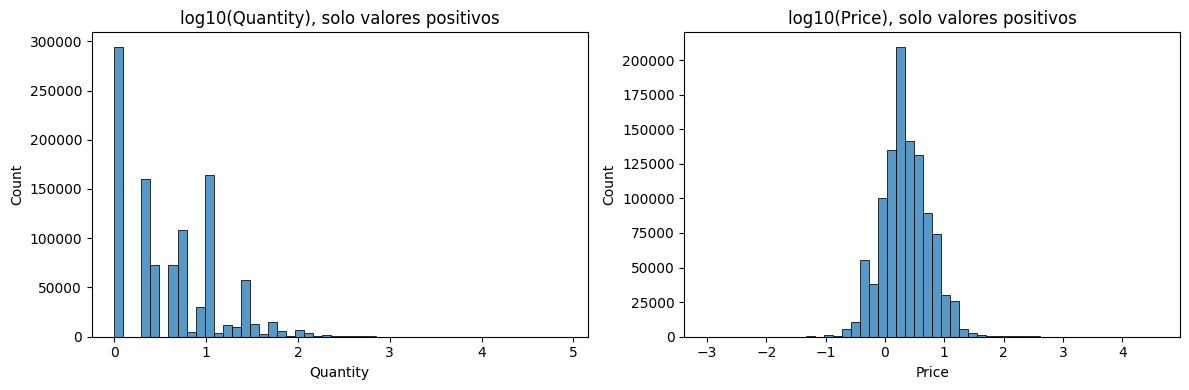

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Para este grafico usamos escala logarítmica porque los valores van de 1 a decenas de miles y en escala normal casi no se ve nada salvo los extremos.
sns.histplot(np.log10(df_raw.loc[df_raw['Quantity'] > 0, 'Quantity']), bins=50, ax=ax[0])
ax[0].set_title('log10(Quantity), solo valores positivos')

sns.histplot(np.log10(df_raw.loc[df_raw['Price'] > 0, 'Price']), bins=50, ax=ax[1])
ax[1].set_title('log10(Price), solo valores positivos')

plt.tight_layout()
plt.show()

- Al obtener una distribucion **larga hacia la derecha** (cola larga), hay pocos valores muy grandes. Eso es un patrón típico de compras: la mayoría compra poco y unos pocos compran mucho.

## 3. EDA

Acá aplicamos la limpieza. Cada paso tiene un motivo:

1. **Eliminar duplicados exactos:** son errores de carga, no compras nuevas.
2. **Eliminar filas sin `Customer ID`:** sin identificador no podemos saber a quién asignar la compra.
3. **Eliminar facturas de cancelación:** son devoluciones, no compras.
4. **Eliminar cantidades y precios no positivos:** no tienen sentido comercial.
5. **Eliminar códigos que no son productos:** portes, descuentos, cargos bancarios.
6. **Convertir el Customer ID a entero:** se guardó como decimal (13085.0) por los nulos; ahora que no hay nulos lo pasamos a entero.
7. **Calcular `Total = Quantity × Price`:** el gasto de cada línea de factura.

In [69]:
codigos_no_producto = ['POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'DOT', 'CRUK']

n0 = len(df_raw)

# Cada línea filtra la tabla. Las condiciones se encadenan una por una.
df = df_raw.drop_duplicates().copy()                                  # 1. sin duplicados
df = df[df['Customer ID'].notna()]                                    # 2. con cliente identificado
df = df[~df['Invoice'].astype(str).str.startswith('C')]               # 3. sin devoluciones
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]                     # 4. valores positivos
df = df[~df['StockCode'].astype(str).isin(codigos_no_producto)]       # 5. solo productos

df['Customer ID'] = df['Customer ID'].astype(int)                     # 6. ID como entero
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Total'] = df['Quantity'] * df['Price']                            # 7. gasto por línea

print(f'Filas originales: {n0:,}')
print(f'Filas después de limpieza: {len(df):,} ({len(df) / n0:.1%} del original)')
print('Clientes únicos:', df['Customer ID'].nunique())
print('Rango de fechas:', df['InvoiceDate'].min(), '->', df['InvoiceDate'].max())

Filas originales: 1,067,371
Filas después de limpieza: 776,872 (72.8% del original)
Clientes únicos: 5862
Rango de fechas: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


- Se conserva aproximadamente **el 73% de las filas**. El resto son duplicados, sin cliente, devoluciones o no productos.
- La cantidad de **clientes únicos** es el número real con el que vamos a trabajar.
- El rango de fechas nos dice el período analizado y nos sirve para elegir la fecha de corte.

### Construir la tabla RFM (un perfil por cliente)

La idea es pasar de **una fila por transacción** a **una fila por cliente**, con sus tres números.

- **Fecha de corte:** es la fecha de referencia para medir la recencia. Usamos la última fecha del dataset + 1 día. Así, la recencia de un cliente que compró el último día es 1, no 0.
- **Recencia:** días entre la fecha de corte y la última compra del cliente.
- **Frecuencia:** cantidad de facturas distintas (`nunique` cuenta valores únicos, para no contar dos veces una misma factura con varias líneas).
- **Monetario:** suma de todos los gastos del cliente.

**Por qué es importante la fecha de corte:** si varia, cambia la recencia de todos los clientes. Por eso se fija una vez, y se documenta.

In [70]:
fecha_corte = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Fecha de corte:', fecha_corte)

rfm = df.groupby('Customer ID').agg(
    Recencia=('InvoiceDate', lambda s: (fecha_corte - s.max()).days),  # días desde la última compra
    Frecuencia=('Invoice', 'nunique'),                                  # facturas distintas
    Monetario=('Total', 'sum'),                                         # gasto total
).reset_index()

print('Clientes en RFM:', len(rfm))
rfm.describe().round(2)

Fecha de corte: 2011-12-10 12:50:00
Clientes en RFM: 5862


,Customer ID,Recencia,Frecuencia,Monetario
count,5862.00,5862.00,5862.00,5862.00
mean,15316.59,200.99,6.25,2914.64
std,1716.17,209.22,12.79,14328.94
min,12346.00,1.00,1.00,2.95
25%,13833.25,26.00,1.00,338.72
50%,15317.50,96.00,3.00,855.22
75%,16799.75,379.00,7.00,2237.03
max,18287.00,739.00,378.00,580987.04


- Cada fila de `rfm` es un cliente. La cantidad de filas debería coincidir con la de clientes únicos de la celda anterior.
- Mirá la columna **max** de Frecuencia y Monetario frente a la **mediana** (50%). Si el máximo está muy lejos de la mediana, hay clientes muy atípicos (mayoristas grandes). Eso es normal en este dataset y lo vamos a tratar con el logaritmo.

### Asimetría y transformación logarítmica

**El problema:** Frecuencia y Monetario tienen una cola muy larga. Un cliente que gasta 50 veces más que la mediana "tira" de los promedios y distorsiona la distancia entre clientes. Los algoritmos de clustering miden distancias, así que los outliers los afectan mucho.

**La solución:** aplicar `log(1 + x)`. El logaritmo comprime los valores grandes y mantiene el orden. El `+1` evita el problema de `log(0)`.

**Cómo medirlo:** la **asimetría (skewness)** indica qué tan desbalanceada es una distribución. Cerca de 0 es simétrica. Mayor a 1 o menor a -1 es muy asimétrica. Comparamos antes y después del logaritmo.

In [71]:
rfm_log = np.log1p(rfm[['Recencia', 'Frecuencia', 'Monetario']])

print(pd.DataFrame({
    'asimetria_original': rfm[['Recencia', 'Frecuencia', 'Monetario']].apply(skew),
    'asimetria_log1p': rfm_log.apply(skew),
}).round(2))

            asimetria_original  asimetria_log1p
Recencia                  0.89            -0.49
Frecuencia               12.14             1.00
Monetario                25.30             0.27


Esperamos que la asimetría **baje** después del logaritmo, sobre todo en Frecuencia y Monetario. Si baja de valores altos (por ejemplo 12 o 25) a valores cercanos a 0 o 1, la transformación cumple su función.

## 4. Modelado y validación

### Esquema de validación

Antes de entrenar nada, dividimos los clientes en dos grupos:

- **Desarrollo o train (80%):** lo usamos para elegir K, eps y entrenar los modelos.
- **Holdout o test (20%):** lo guardamos aparte. **No participa en ninguna decisión.** Sirve para testear que el modelo funciona con clientes que nunca vio.

- El **escalado** (StandardScaler) se calcula **solo con el 80% asignado al entrenamiento**, y después se aplica al 20% restante de testeo. Si lo calculáramos con todos, la información del test se filtraría al entrenamiento.
- Las métricas para medir clusters no usan etiquetas verdaderas (no hay "respuesta correcta"), sino qué tan compactos y separados están los grupos.

In [72]:
# Dividimos los índices de los clientes: 80% desarrollo, 20% holdout
idx_dev, idx_hold = train_test_split(rfm.index, test_size=0.20, random_state=RANDOM_STATE)

X_dev_raw = rfm_log.loc[idx_dev]
X_hold_raw = rfm_log.loc[idx_hold]

# StandardScaler: resta la media y divide por el desvío de cada columna.
# Así las tres variables tienen la misma escala y ninguna domina la distancia.
# Lo ajustamos (fit) SOLO con desarrollo y lo aplicamos (transform) a los dos.
scaler = StandardScaler().fit(X_dev_raw)
X_dev = scaler.transform(X_dev_raw)
X_hold = scaler.transform(X_hold_raw)

print('train:', X_dev.shape, '| test:', X_hold.shape)

train: (4689, 3) | test: (1173, 3)


### Metricas a evaluar

- **Silhouette (entre -1 y 1):** mide para cada cliente la distancia al centroide del cluster. **Más alto = mejor.** Por encima de 0,5 se considera muy bueno; entre 0,25 y 0,5, razonable para datos reales.
- **Davies-Bouldin (≥ 0):** mide la relación entre dispersión dentro de cada grupo y separación entre grupos. **Más bajo = mejor.**
- **Inercia (codo):** suma de distancias cuadradas de cada cliente a su centroide. Siempre baja al aumentar K, así que buscamos el "codo": donde la baja deja de ser importante.
- **% de ruido (DBSCAN):** clientes que el algoritmo no asigna a ningún grupo. Un porcentaje alto indica que los parámetros no son adecuados.


In [73]:
def metricas(X, labels):
    # El ruido de DBSCAN se marca como -1. No lo contamos como grupo al medir.
    mask = labels != -1
    n = len(set(labels[mask]))
    out = {'n_segmentos': n, '% ruido': round((~mask).mean() * 100, 1)}
    if n >= 2:
        out['silhouette'] = round(silhouette_score(X[mask], labels[mask]), 3)
        out['davies_bouldin'] = round(davies_bouldin_score(X[mask], labels[mask]), 3)
    return out

### 4.1 Elegir K para K-Means

Probamos K entre 2 y 8, y para cada uno medimos inercia, Silhouette y Davies-Bouldin.

- Miramos el **codo**: el punto donde la curva deja de caer fuerte.
- Miramos el **Silhouette**: buscamos un máximo local.

,k,inercia,silhouette,davies_bouldin
0,2,6858.0,0.438,0.875
1,3,5061.4,0.346,1.040
2,4,3894.4,0.367,0.930
3,5,3248.2,0.342,0.957
4,6,2822.4,0.338,0.960
5,7,2538.7,0.319,0.995
6,8,2305.9,0.295,0.991


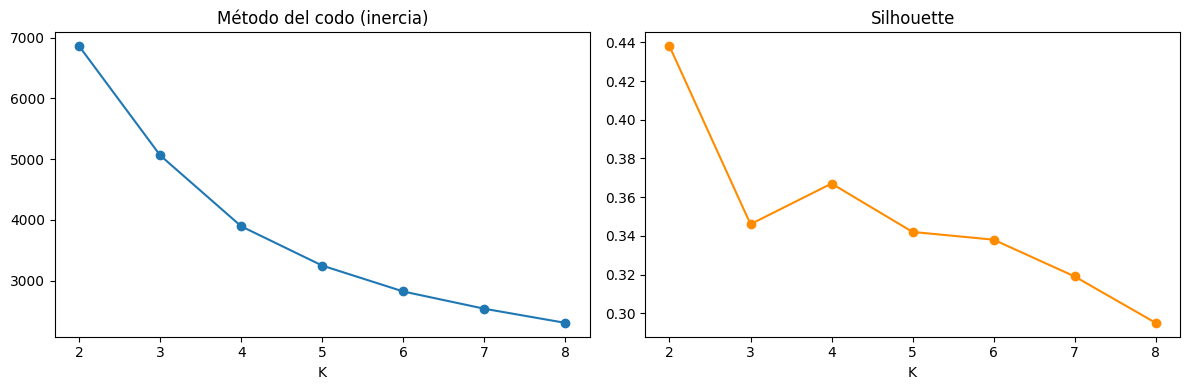

In [74]:
filas_k = []
for k in range(2, 9):
    # n_init=10: corre K-Means 10 veces con distintos puntos de partida y se queda con la mejor
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_dev)
    m = metricas(X_dev, km_k.labels_)
    m['k'] = k
    m['inercia'] = round(km_k.inertia_, 1)
    filas_k.append(m)

tabla_k = pd.DataFrame(filas_k).reindex(columns=['k', 'inercia', 'silhouette', 'davies_bouldin'])
display(tabla_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tabla_k['k'], tabla_k['inercia'], marker='o')
ax[0].set_title('Método del codo (inercia)'); ax[0].set_xlabel('K')
ax[1].plot(tabla_k['k'], tabla_k['silhouette'], marker='o', color='darkorange')
ax[1].set_title('Silhouette'); ax[1].set_xlabel('K')
plt.tight_layout(); plt.show()

- En la tabla la columna `silhouette` nos da el valor más alto indica el K "estadísticamente" mejor.
- Por otro lado, el gráfico del codo, buscá dónde la curva se aplana. Es el K donde agregar otro grupo ya no aporta mucho.
- En este caso ambos criterios no coinciden, ya que en base a `silhouette` deberiamos usar K=2 pero en base a la curva de codo nos da mejor usar K=4 ya que se ajusta mejor a nuestro modelo de negocio.

### 4.2 Dendrograma de Ward (para justificar el jerárquico)

El clustering jerárquico arma los grupos de a poco, uniendo primero a los clientes más parecidos, y así sucesivamente. El dendrograma muestra esa historia como un árbol. La altura de cada unión indica cuán distintos eran los grupos que se unieron.

Si hay una unión "alta" (una rama larga sin unirse), esa altura sugiere un corte natural. Cortar el árbol a esa altura da el número de grupos.

Mostramos solo los últimos 30 nodos porque con miles de clientes el árbol completo es ilegible.

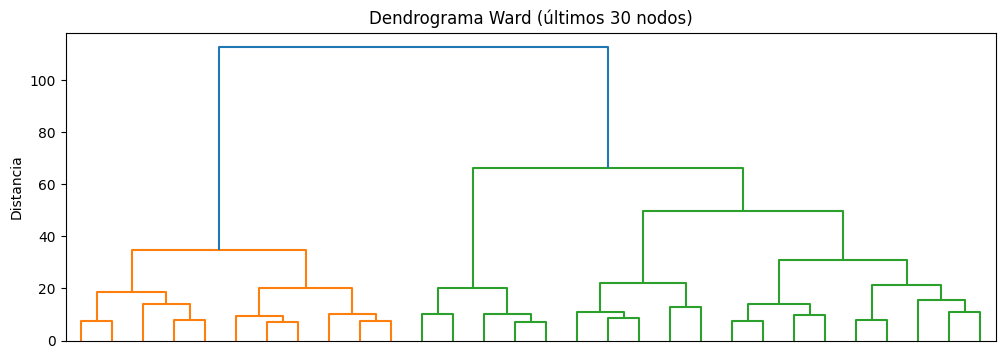

In [75]:
# linkage: arma el árbol de uniones usando el criterio Ward (minimiza la varianza dentro de cada grupo)
Z = linkage(X_dev, method='ward')

plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode='lastp', p=30, no_labels=True)
plt.title('Dendrograma Ward (últimos 30 nodos)')
plt.ylabel('Distancia')
plt.show()

Aqui contamos cuántas ramas verticales "grandes" hay por encima de un umbral razonable. Si la altura más grande de la última unión está muy por encima de las demás, sugiere pocos grupos. En este caso tambien aportaria a elegir K=2, pero el modelo de negocio nos sigue siendo mas conveniente usar un K=4

### 4.3 Elegir eps para DBSCAN

**Qué es DBSCAN:** en vez de fijar K, busca zonas **densas** de clientes. Un cliente es parte de un grupo si tiene al menos `MIN_SAMPLES` vecinos a distancia menor que `eps`. Los clientes que quedan aislados se marcan como **ruido** (-1).

**Los dos parámetros:**
- `MIN_SAMPLES` (aquí 10): cuántos vecinos hacen falta para considerar a un punto como parte de un grupo denso.
- `eps`: radio de vecindad. Es el parámetro más sensible.

**Cómo elegir eps:** el gráfico de "k-distance" calcula, para cada cliente, la distancia a su vecino número `MIN_SAMPLES`. Ordenamos esas distancias de menor a mayor. El **codo** de la curva (donde sube bruscamente) sugiere un buen eps. Después probamos varios valores en la tabla.

**Qué buscamos en la tabla:** un eps con pocos clientes como ruido (menos del 15%), y con al menos 2 grupos con Silhouette razonable.

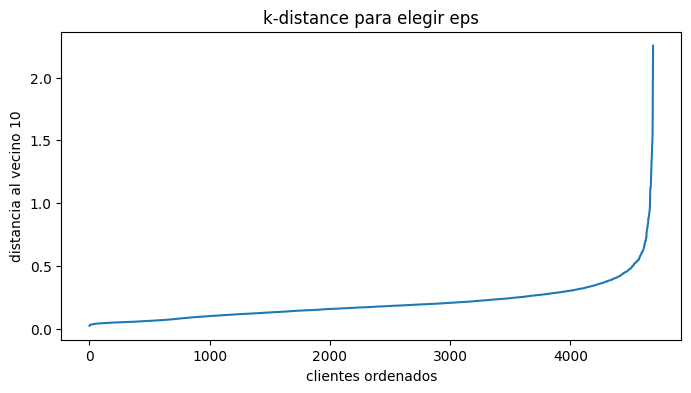

,eps,n_segmentos,% ruido,silhouette,davies_bouldin
0,0.2,11,25.1,-0.012,1.709
1,0.3,3,7.9,0.162,1.688
2,0.4,2,2.9,0.280,1.012
3,0.5,2,1.5,0.277,1.017
4,0.6,1,0.8,NaN,NaN
5,0.8,1,0.5,NaN,NaN
6,1.0,1,0.3,NaN,NaN


In [76]:
# Gráfico k-distance: distancia de cada cliente a su vecino número MIN_SAMPLES
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_dev)
dist, _ = nn.kneighbors(X_dev)

plt.figure(figsize=(8, 4))
plt.plot(np.sort(dist[:, -1]))
plt.ylabel(f'distancia al vecino {MIN_SAMPLES}')
plt.xlabel('clientes ordenados')
plt.title('k-distance para elegir eps')
plt.show()

# Probamos varios valores de eps y medimos los resultados
filas_db = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X_dev).labels_
    m = metricas(X_dev, lab)
    m['eps'] = eps
    filas_db.append(m)

tabla_db = pd.DataFrame(filas_db).reindex(columns=['eps', 'n_segmentos', '% ruido', 'silhouette', 'davies_bouldin'])
display(tabla_db)

- **eps chico:** muchos clientes quedan como ruido y puede haber muchos grupos chicos.
- **eps grande:** casi todos caen en un solo grupo gigante, y el Silhouette no significa mucho.
- Aqui la idea es buscar un eps que tenga **% ruido bajo** y **2 o más grupos** con Silhouette razonable. Si ningún eps cumple, DBSCAN no sera adecuado para estos datos.

El eps a elegir es 0.5 ya que es donde se evidencia el quiebre del codo.

### 4.4 Ajustar los tres modelos y evaluar en holdout

**Problema técnico:** K-Means tiene un método `predict` que asigna clientes nuevos a un grupo. **Ward y DBSCAN no lo tienen.** Por eso les damos una regla propia para el holdout:

- **Ward:** el cliente del test se asigna al grupo cuyo centro (centroide) esté más cerca.
- **DBSCAN:** el cliente del test entra al grupo de su vecino más cercano del desarrollo, **si está dentro de eps**. Si no, queda como ruido.

**Por qué importa:** si un modelo funciona bien en desarrollo pero se derrumba en testeo, sobreajustó. Queremos que los grupos sigan siendo buenos con clientes nuevos.

In [77]:
def asignar_por_centroide(X_ref, labels_ref, X_nuevo):
    # Centroide de cada grupo = promedio de sus clientes.
    # Cada cliente nuevo va al centroide más cercano.
    ids = [c for c in np.unique(labels_ref) if c != -1]
    centroides = np.vstack([X_ref[labels_ref == c].mean(axis=0) for c in ids])
    d = np.linalg.norm(X_nuevo[:, None, :] - centroides[None, :, :], axis=2)
    return np.array(ids)[d.argmin(axis=1)]

def asignar_dbscan(X_ref, labels_ref, X_nuevo, eps):
    # Cada cliente nuevo toma la etiqueta de su vecino más cercano del desarrollo.
    # Si ese vecino está a más de eps, el cliente nuevo es ruido (-1).
    mask = labels_ref != -1
    vecino = NearestNeighbors(n_neighbors=1).fit(X_ref[mask])
    dist, idx = vecino.kneighbors(X_nuevo)
    lab = labels_ref[mask][idx[:, 0]].copy()
    lab[dist[:, 0] > eps] = -1
    return lab

# --- K-Means ---
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_dev)
lab_km_dev = km.labels_
lab_km_hold = km.predict(X_hold)

# --- Jerárquico Ward ---
ag = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X_dev)
lab_ag_dev = ag.labels_
lab_ag_hold = asignar_por_centroide(X_dev, lab_ag_dev, X_hold)

# --- DBSCAN ---
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X_dev)
lab_db_dev = db.labels_
lab_db_hold = asignar_dbscan(X_dev, lab_db_dev, X_hold, EPS)

print('K-Means dev:', np.bincount(lab_km_dev))
print('Ward dev:', np.bincount(lab_ag_dev))
print('DBSCAN dev (-1 = ruido):', dict(zip(*np.unique(lab_db_dev, return_counts=True))))

K-Means dev: [1566  941 1172 1010]
Ward dev: [1075 1331 1217 1066]
DBSCAN dev (-1 = ruido): {np.int64(-1): np.int64(68), np.int64(0): np.int64(3318), np.int64(1): np.int64(1303)}


Cada línea muestra cuántos clientes quedaron en cada grupo del desarrollo. Si un grupo tiene muy pocos clientes (menos del 5%), el modelo está creando un grupo muy chico que probablemente no sea accionable.

### 4.5 Linea de base o benchmark de negocio: quintiles RFM

La forma tradicional de segmentar en marketing. Se ordena a los clientes por cada variable en 5 partes iguales (quintiles) y se les asigna un puntaje de 1 a 5. Después se suman los tres puntajes.

- Para **Recencia**, invertimos la escala: menos días = puntaje 5 (el cliente está más activo).
- Para **Frecuencia** y **Monetario**, más = puntaje 5.
- El puntaje total va de 3 a 15. Lo agrupamos en 4 tramos para poder compararlo con K=4.

**Por qué lo incluimos:** es el "piso" contra el que medimos a los algoritmos. Si K-Means no lo supera, el clustering no agrega valor frente a la regla de siempre.

**Por qué usamos `rank` antes de `qcut`:** los quintiles tienen que dividir por cantidad de clientes, no por valor. Si hay muchos clientes con el mismo valor, `rank(method='first')` los desempata para que cada quintil tenga aproximadamente el mismo tamaño.

In [78]:
r_score = pd.qcut(rfm['Recencia'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
f_score = pd.qcut(rfm['Frecuencia'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
m_score = pd.qcut(rfm['Monetario'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['RFM_score'] = r_score + f_score + m_score
rfm['Seg_quintil'] = pd.cut(rfm['RFM_score'], bins=[2, 6, 9, 12, 15], labels=[0, 1, 2, 3]).astype(int)

lab_q_dev = rfm.loc[idx_dev, 'Seg_quintil'].values
lab_q_hold = rfm.loc[idx_hold, 'Seg_quintil'].values
print('Quintiles dev:', np.bincount(lab_q_dev))

Quintiles dev: [1426 1178 1078 1007]


Los quintiles dan grupos de tamaño parecido por construcción. Esto es una diferencia de fondo con K-Means: los algoritmos encuentran grupos según la estructura de los datos, y los quintiles los cortan por reglas fijas.

### 4.6 Tabla comparativa final

Compara los cuatro enfoques con las mismas métricas, para entrenamiento y testeo.

- **Silhouette holdout** cerca de **Silhouette dev** = el modelo es estable (no sobreajustó).
- Si el holdout cae mucho, desconfiamos del modelo.
- Comparamos contra el benchmark: un algoritmo sirve si supera claramente a los quintiles.

In [79]:
filas = []
modelos = [
    ('Quintiles RFM (benchmark)', lab_q_dev, lab_q_hold),
    ('K-Means', lab_km_dev, lab_km_hold),
    ('Jerárquico Ward', lab_ag_dev, lab_ag_hold),
    ('DBSCAN', lab_db_dev, lab_db_hold),
]
for nombre, ld, lh in modelos:
    m_dev = metricas(X_dev, ld)
    m_hold = metricas(X_hold, lh)
    filas.append({
        'Modelo': nombre,
        'Segmentos (dev)': m_dev['n_segmentos'],
        'Silhouette dev': m_dev.get('silhouette'),
        'Silhouette test': m_hold.get('silhouette'),
        'Davies-Bouldin dev': m_dev.get('davies_bouldin'),
        'Davies-Bouldin test': m_hold.get('davies_bouldin'),
        '% ruido dev': m_dev['% ruido'],
    })

tabla_final = pd.DataFrame(filas)
tabla_final

,Modelo,Segmentos (dev),Silhouette dev,Silhouette test,Davies-Bouldin dev,Davies-Bouldin test,% ruido dev
0,Quintiles RFM (benchmark),4,0.239,0.226,1.531,1.536,0.0
1,K-Means,4,0.367,0.356,0.930,0.929,0.0
2,Jerárquico Ward,4,0.329,0.350,0.993,0.934,0.0
3,DBSCAN,2,0.277,0.287,1.017,0.962,1.5


## 5. Evaluación y elección del modelo

### Regla de selección

1. **Criterio principal:** mayor Silhouette en desarrollo.
2. **Desempate:** estabilidad (diferencia pequeña entre Silhouette de desarrollo y de testeo).
3. **Desempate final:** interpretabilidad. Ningún segmento debería tener menos del 5% de los clientes.

In [80]:
MODELO_FINAL = 'K-Means'   # opciones: 'K-Means', 'Jerárquico Ward', 'DBSCAN'

lab_final_dev = {'K-Means': lab_km_dev, 'Jerárquico Ward': lab_ag_dev, 'DBSCAN': lab_db_dev}[MODELO_FINAL]
lab_final_hold = {'K-Means': lab_km_hold, 'Jerárquico Ward': lab_ag_hold, 'DBSCAN': lab_db_hold}[MODELO_FINAL]
print('Modelo elegido:', MODELO_FINAL)

Modelo elegido: K-Means


## 6. Interpretación para el negocio

Acá pasamos de números a decisiones. Para cada segmento calculamos su perfil en **unidades originales** (días, facturas, libras), que son las que entiende marketing. Usamos solo el 80% de desarrollo para no mirar el holdout.

In [81]:
perfil = rfm.loc[idx_dev].assign(Segmento=lab_final_dev)
perfil = perfil[perfil['Segmento'] != -1]   # descartamos el ruido de DBSCAN si lo hubiera

resumen = perfil.groupby('Segmento').agg(
    Clientes=('Customer ID', 'size'),
    Recencia_mediana=('Recencia', 'median'),
    Frecuencia_mediana=('Frecuencia', 'median'),
    Monetario_mediano=('Monetario', 'median'),
    Ingreso_total=('Monetario', 'sum'),
)
resumen['% clientes'] = (resumen['Clientes'] / resumen['Clientes'].sum() * 100).round(1)
resumen['% ingresos'] = (resumen['Ingreso_total'] / resumen['Ingreso_total'].sum() * 100).round(1)
resumen = resumen.sort_values('Monetario_mediano', ascending=False)
resumen.round(1)

,Clientes,Recencia_mediana,Frecuencia_mediana,Monetario_mediano,Ingreso_total,% clientes,% ingresos
Segmento,,,,,,,
1,941,16.0,13.0,4921.5,9159237.3,20.1,72.0
2,1172,185.0,4.0,1440.7,2250981.9,25.0,17.7
3,1010,24.0,3.0,708.4,824203.7,21.5,6.5
0,1566,404.0,1.0,271.5,491622.5,33.4,3.9


- **Recencia mediana bajo:** los clientes de ese segmento compraron recientemente.
- **Frecuencia y Monetario medianos altos:** compran seguido y gastan mucho.
- **% ingresos vs. % clientes:** si un segmento tiene poco % de clientes pero mucho % de ingresos, es el más valioso. Es el dato más fuerte para el informe.
- Usamos la **mediana** y no el promedio porque la mediana no se distorsiona con los pocos clientes muy grandes.

Con estos perfiles, asignamos un nombre a cada segmento.

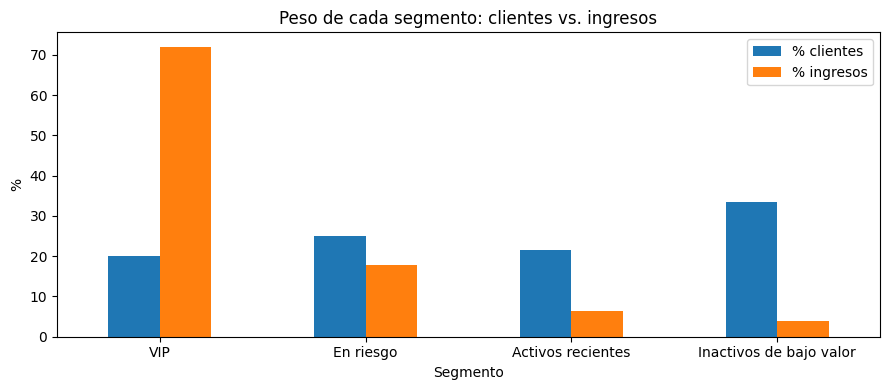

In [84]:
NOMBRES = {1: 'VIP', 2: 'En riesgo', 3: 'Activos recientes', 0: 'Inactivos de bajo valor'}

ax = resumen[['% clientes', '% ingresos']].rename(index=lambda i: NOMBRES.get(i, f'Segmento {i}')).plot(kind='bar', figsize=(9, 4))
ax.set_title('Peso de cada segmento: clientes vs. ingresos')
ax.set_ylabel('%')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Si una barra de ingresos es mucho más alta que la de clientes (el caso de los clientes VIP), ese segmento concentra el valor del negocio. Eso define a quién proteger primero.

## 7. Ética, privacidad y limitaciones

**Privacidad:** el dataset usa un `Customer ID` anonimizado. No tiene nombre, dirección ni contacto. Trabajamos con agregados por cliente. En un entorno real, habría que aplicar minimización de datos (usar solo lo necesario) y controles de acceso.

**Sesgo y representatividad:** el dataset es de un comercio mayorista-minorista británico, entre 2009 y 2011. Sus conclusiones no se trasladan automáticamente a otros mercados ni a clientes actuales.

**Limitaciones técnicas:**
- K-Means asume grupos con forma esférica y no es robusto a outliers.
- DBSCAN puede marcar como ruido a clientes muy atípicos, como los grandes mayoristas.
- La recencia depende de la fecha de corte elegida.
- El Silhouette obtenido (alrededor de 0,36 en train y test para K-Means) no alcanza la meta de 0,45 fijada en la pre-entrega. Los clientes no forman grupos muy separados, y los segmentos se solapan en parte. Los segmentos siguen siendo útiles para negocio, pero la separación estadística es moderada.

**Riesgo de uso:** un segmento "En riesgo" no debe usarse para negar descuentos o beneficios a clientes de bajo valor sin revisión humana.

In [83]:
# Exportamos la segmentación final: todos los clientes, con su segmento y su nombre
seg_all = pd.concat([
    pd.Series(lab_final_dev, index=idx_dev),
    pd.Series(lab_final_hold, index=idx_hold),
]).sort_index()

salida = rfm.assign(Segmento=seg_all)
salida['Nombre_segmento'] = salida['Segmento'].map(NOMBRES)
salida.to_csv('segmentos_clientes.csv', index=False)
print('Exportado: segmentos_clientes.csv', salida.shape)

try:
    from google.colab import files
    files.download('segmentos_clientes.csv')
except ImportError:
    pass

Exportado: segmentos_clientes.csv (5862, 8)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>